# 09 · Final Evaluation
The project's question: **can a temporal knowledge graph of six months of card behaviour provide useful information for credit-risk modelling and for explainable credit-increase analysis?**

This notebook pulls the evidence together and adds the checks that only make sense at the end:
1. **Pipeline health check**: data, graph, tests and wording still hold.
2. **What the data and graph showed** (summary of notebooks 02–05).
3. **Ablation table with confidence intervals**: does the graph help, and for which model?
4. **Calibration** of the probability model the score uses.
5. **Credit-increase score**: how its labels relate to real outcomes.
6. **Fairness audit** of the score across sex, age, education and marital status.
7. **Limitations** and a **plain-language conclusion**.

Everything is read from files written by notebooks 01–08. No model is tuned here and the test set drives no choice.
The final cell writes `outputs/reports/final_report.md` and `outputs/reports/phase9_results.json` from the computed numbers.

**Setup.** Imports, shared colours for the figures, and `R`, a dictionary that collects every number the final report quotes.

In [1]:
import sys, pathlib, json, pickle, subprocess, re, warnings
sys.path.insert(0, str(pathlib.Path.cwd().parent / "src"))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)
from credit_kg import config as C, modeling as M, scoring as S, evaluation as E, stats as ST, report as REP
BLUE, ORANGE, INK, INK2, MUTED, GRID = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e", "#898781", "#e1e0d9"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#c3c2b7",
                     "axes.labelcolor": INK2, "xtick.color": MUTED, "ytick.color": MUTED, "figure.dpi": 110})
R = {}

## 1. Pipeline health check

**Data.** The prepared tables still have 30,000 unique customers and 180,000 monthly rows, and the fixed split keeps a 20% test set with the same default rate on both sides.

In [2]:
wide = pd.read_parquet(C.PROCESSED / "customers.parquet")
monthly = pd.read_parquet(C.PROCESSED / "monthly.parquet")
split = pd.read_csv(C.PROCESSED / "split.csv")
ws = wide.merge(split)
health = {"customers": len(wide), "monthly_rows": len(monthly), "unique_ids": bool(wide.customer_id.is_unique),
          "test_share": float((split.split == "test").mean()),
          "default_rate_train": float(ws.loc[ws.split == "train", C.TARGET].mean()),
          "default_rate_test": float(ws.loc[ws.split == "test", C.TARGET].mean())}
assert health["customers"] == 30000 and health["monthly_rows"] == 180000 and health["unique_ids"]
R["health"] = health
pd.Series(health)

customers                30000
monthly_rows            180000
unique_ids                True
test_share                 0.2
default_rate_train    0.221208
default_rate_test     0.221167
dtype: object

**Graph.** Exact node and relationship counts, `NEXT_MONTH` only links a month to the next one, and no node or relationship carries the outcome. Needs Neo4j; if it is not running, the check is reported as skipped rather than passed.

In [3]:
expected = {"customers": 30000, "accounts": 30000, "monthly_records": 180000, "states": 5,
            "HAS_ACCOUNT": 30000, "HAS_MONTHLY_RECORD": 180000, "NEXT_MONTH": 150000, "IN_STATE": 180000}
try:
    from credit_kg import graph as G
    driver = G.get_driver()
    counts = G.graph_counts(driver)
    leak_nodes = int(G.run(driver, "MATCH (n) WHERE any(k IN keys(n) WHERE toLower(k) CONTAINS 'default' OR k IN ['target', 'label']) RETURN count(n) AS n")["n"][0])
    leak_rels = int(G.run(driver, "MATCH ()-[r]->() WHERE any(k IN keys(r) WHERE toLower(k) CONTAINS 'default' OR k IN ['target', 'label']) RETURN count(r) AS n")["n"][0])
    bad_order = int(G.run(driver, "MATCH (a:MonthlyCreditRecord)-[:NEXT_MONTH]->(b) WHERE b.month_index <> a.month_index + 1 RETURN count(*) AS n")["n"][0])
    driver.close()
    graph_check = {"status": "checked", "counts_match": counts == expected, "counts": counts,
                   "outcome_properties_on_nodes": leak_nodes, "outcome_properties_on_relationships": leak_rels,
                   "next_month_out_of_order": bad_order}
    assert graph_check["counts_match"] and leak_nodes == 0 and leak_rels == 0 and bad_order == 0
except Exception as exc:
    if isinstance(exc, AssertionError):
        raise
    graph_check = {"status": f"skipped: Neo4j not reachable ({type(exc).__name__})"}
R["graph"] = graph_check
graph_check

{'status': 'checked',
 'counts_match': True,
 'counts': {'customers': 30000,
  'accounts': 30000,
  'monthly_records': 180000,
  'states': 5,
  'HAS_ACCOUNT': 30000,
  'HAS_MONTHLY_RECORD': 180000,
  'NEXT_MONTH': 150000,
  'IN_STATE': 180000},
 'outcome_properties_on_nodes': 0,
 'outcome_properties_on_relationships': 0,
 'next_month_out_of_order': 0}

**Test suite.** Runs every pytest test in the project (about a minute). The notebook stops if any test fails.

In [4]:
proc = subprocess.run([sys.executable, "-m", "pytest", "tests", "-q"], cwd=C.ROOT, capture_output=True, text=True)
summary_line = [l for l in proc.stdout.strip().splitlines() if "passed" in l or "failed" in l][-1]
R["tests"] = {"returncode": proc.returncode, "summary": summary_line}
print(summary_line)
assert proc.returncode == 0, proc.stdout[-3000:]

32 passed in 6.76s


**Terminology lint.** Card payments are payment behaviour, never income. We list every line in the docs, code, config and notebooks 01–08 that mentions *income* or *salary* and flag any that is not phrased as a negation.

In [5]:
NEG = re.compile(r"\b(not|never|no|nor|without)\b", re.I)
WORD = re.compile(r"income|salary", re.I)
sources = [C.ROOT / "README.md", C.ROOT / "main.py", *sorted((C.ROOT / "docs").glob("*.md")),
           *sorted((C.ROOT / "src").rglob("*.py")), *sorted(C.CONFIG_DIR.glob("*.yaml"))]
texts = {p: p.read_text(encoding="utf-8") for p in sources}
for p in sorted((C.ROOT / "notebooks").glob("0[1-8]_*.ipynb")):
    texts[p] = "\n".join("".join(c["source"]) for c in json.loads(p.read_text(encoding="utf-8"))["cells"])
hits = [{"file": p.relative_to(C.ROOT).as_posix(), "line": line.strip()[:140], "negated": bool(NEG.search(line)),
         "describes_this_check": "lint" in line.lower()}
        for p, txt in texts.items() for line in txt.splitlines() if WORD.search(line)]
lint = pd.DataFrame(hits, columns=["file", "line", "negated", "describes_this_check"])
flagged = lint[~lint.negated & ~lint.describes_this_check]
R["lint"] = {"lines_mentioning": len(lint), "not_negated": int((~lint.negated).sum()),
             "self_references": int((~lint.negated & lint.describes_this_check).sum()),
             "problems": len(flagged), "problem_lines": flagged.to_dict("records")}
print(f"{len(lint)} lines mention income/salary; {(~lint.negated).sum()} not phrased as a negation, "
      f"of which {R['lint']['self_references']} only describe this check; problems: {len(flagged)}")
lint[~lint.negated]

12 lines mention income/salary; 2 not phrased as a negation, of which 2 only describe this check; problems: 0


,file,line,negated,describes_this_check
6,docs/PLAN.md,| PAY_AMT as income | Terminology lint: grep o...,False,True
9,src/credit_kg/report.py,"f""- Terminology: {R['lint']['lines_mentioning'...",False,True


## 2. What the data and the graph showed

**Validated and rejected behaviour patterns** (notebook 03, training customers). `rate_low_bucket` and `rate_high_bucket` are the default rates in the lowest and highest bucket of each measure.

In [6]:
pv = pd.read_csv(C.TABLES / "pattern_validation.csv")
R["patterns"] = pv[["hypothesis", "verdict", "rate_low_bucket", "rate_high_bucket", "single_feature_auc"]].to_dict("records")
pv[["hypothesis", "verdict", "rate_low_bucket", "rate_high_bucket", "single_feature_auc"]]

,hypothesis,verdict,rate_low_bucket,rate_high_bucket,single_feature_auc
0,H1 higher utilization -> more default,NOT SUPPORTED (non-monotone shape),0.3580,0.3504,0.568
1,"H1b same, active users only (util > 10%)",SUPPORTED,0.1602,0.3504,0.595
2,H2 more late months -> more default,SUPPORTED,0.1151,0.6972,0.729
3,H3 higher payment coverage -> less default,SUPPORTED,0.5772,0.1683,0.589
4,H4 rising utilization (slope) -> more default,NOT SUPPORTED (opposite direction),0.2990,0.2140,0.554
5,H5 rising payments (slope) -> less default,NOT SUPPORTED (non-monotone shape),0.2208,0.2119,0.512
6,H6 rising bills (slope) -> more default,NOT SUPPORTED (opposite direction),0.2985,0.2140,0.554
7,H7 less consistent payments (CV) -> more default,PARTLY (mostly in expected direction),0.1915,0.2044,0.517
8,H8 higher credit limit -> less default,SUPPORTED,0.3217,0.1308,0.623
9,H9 larger typical payment -> less default,SUPPORTED,0.2842,0.1277,0.601


**Patterns found by Cypher in the graph** (notebook 05). The graph never sees the outcome; default rates are joined afterwards. Train and test agree, so these are not one-sample flukes.

In [7]:
gp = pd.read_csv(C.TABLES / "graph_pattern_validation.csv")
R["graph_patterns"] = gp.to_dict("records")
gp

,pattern,customers,train_default_rate,train_ci,test_default_rate,test_ci,lift_vs_base
0,Q1 late in >=3 of 6 months,3744,0.599,"[0.581, 0.616]",0.603,"[0.568, 0.638]",2.71
1,Q2 late >=3 months in a row,3297,0.604,"[0.585, 0.623]",0.604,"[0.567, 0.641]",2.73
2,Q3 utilization >=90% in >=3 months,5062,0.305,"[0.291, 0.319]",0.285,"[0.258, 0.313]",1.38
3,Q4 utilization rose >=3 months running,1300,0.193,"[0.170, 0.218]",0.225,"[0.178, 0.281]",0.87
4,Q5 recovered and clean in last 3 months,1629,0.235,"[0.213, 0.259]",0.184,"[0.146, 0.230]",1.06
5,Q6 paid <10% of statement in >=3 months,15433,0.267,"[0.259, 0.275]",0.261,"[0.246, 0.277]",1.21
6,"Q7 always paid in full, never late",3652,0.118,"[0.107, 0.130]",0.120,"[0.099, 0.146]",0.53
7,Q8 >=2 concerning signals,8149,0.429,"[0.417, 0.442]",0.418,"[0.394, 0.442]",1.94
8,"Q10 relapse (late, recovered, late again)",1073,0.544,"[0.511, 0.576]",0.525,"[0.452, 0.598]",2.46


## 3. Ablation: does the graph help, and for which model?

**Cross-validation, 25 identical folds** (5 × 5 repeated, training customers only). For each feature set we show the mean ROC-AUC with a **corrected 95% interval**, and the difference from its reference model with its own interval.
The correction (Nadeau & Bengio) matters: CV folds share most of their training data, so a plain interval would be too narrow and would overstate certainty.
The extra ablations (raw-only, no-population, graph-only, demographics) were only ever run in CV; the test set is used once per *final* model.

In [8]:
fs = M.feature_sets()
n_cv = int((split.split == "train").sum())
n_tr, n_te = int(n_cv * 0.8), int(n_cv * 0.2)
specs = [("Random Forest", "A0_raw", "raw monthly columns only", "A0_raw", "A"),
         ("Random Forest", "A", "baseline: raw + engineered (reference)", "A", None),
         ("Random Forest", "B", "baseline + 9 graph features", "B", "A"),
         ("Random Forest", "B_no_population", "baseline + 7 graph features (no transition network)", "B_no_population", "A"),
         ("Random Forest", "graph_only", "credit limit + 9 graph features", "graph_only", "A"),
         ("Random Forest", "A_demo", "baseline + demographics (ablation only)", "A_demo", "A"),
         ("Logistic regression", "LR-A", "baseline (reference)", "A", None),
         ("Logistic regression", "LR-B", "baseline + 9 graph features", "B", "LR-A")]
folds = {s[1]: pd.read_csv(C.TABLES / f"cv_folds_{s[1]}.csv") for s in specs}
assert all((f.fold.to_numpy() == np.arange(25)).all() for f in folds.values())
rows = []
for model, name, desc, fset, ref in specs:
    auc, auc_lo, auc_hi = E.cv_mean_ci(folds[name].roc_auc, n_tr, n_te)
    pr, pr_lo, pr_hi = E.cv_mean_ci(folds[name].pr_auc, n_tr, n_te)
    row = {"model": model, "feature_set": name, "description": desc, "n_features": len(fs[fset]),
           "cv_roc_auc": auc, "roc_ci_low": auc_lo, "roc_ci_high": auc_hi, "cv_pr_auc": pr, "pr_ci_low": pr_lo, "pr_ci_high": pr_hi}
    if ref:
        diff = folds[name].roc_auc - folds[ref].roc_auc
        d, d_lo, d_hi = E.cv_mean_ci(diff, n_tr, n_te)
        tt = M.corrected_resampled_ttest(diff, n_tr, n_te)
        row.update({"reference": ref, "delta_roc_auc": d, "delta_ci_low": d_lo, "delta_ci_high": d_hi,
                    "folds_better": f"{tt['folds_b_better']}/{tt['folds']}", "p_value": tt["p_value"]})
    rows.append(row)
ablation_cv = pd.DataFrame(rows)
ablation_cv.to_csv(C.TABLES / "final_ablation_cv.csv", index=False)
R["ablation_cv"] = ablation_cv.replace({np.nan: None}).to_dict("records")
ablation_cv.drop(columns=["description"]).round(4)

,model,feature_set,n_features,cv_roc_auc,roc_ci_low,roc_ci_high,cv_pr_auc,pr_ci_low,pr_ci_high,reference,delta_roc_auc,delta_ci_low,delta_ci_high,folds_better,p_value
0,Random Forest,A0_raw,19,0.7845,0.7766,0.7925,0.5555,0.5426,0.5683,A,-0.0035,-0.0053,-0.0017,1/25,0.0005
1,Random Forest,A,37,0.7880,0.7805,0.7955,0.5612,0.5478,0.5746,NaN,NaN,NaN,NaN,NaN,NaN
2,Random Forest,B,46,0.7879,0.7804,0.7955,0.5611,0.5479,0.5743,A,-0.0001,-0.0008,0.0007,12/25,0.8228
3,Random Forest,B_no_population,44,0.7878,0.7804,0.7953,0.5610,0.5474,0.5747,A,-0.0002,-0.0009,0.0006,10/25,0.6559
4,Random Forest,graph_only,10,0.7704,0.7626,0.7782,0.5433,0.5303,0.5564,A,-0.0176,-0.0221,-0.0131,0/25,0.0000
5,Random Forest,A_demo,41,0.7887,0.7812,0.7963,0.5627,0.5494,0.5761,A,0.0007,-0.0002,0.0017,19/25,0.1297
6,Logistic regression,LR-A,37,0.7665,0.7572,0.7757,0.5092,0.4963,0.5221,NaN,NaN,NaN,NaN,NaN,NaN
7,Logistic regression,LR-B,46,0.7717,0.7640,0.7793,0.5268,0.5123,0.5413,LR-A,0.0052,0.0023,0.0081,24/25,0.0011


**The four final models on the test set.** We rebuild each model's test predictions from the saved model (forest A and B) or the same deterministic recipe (logistic regression), and first check they reproduce the numbers notebooks 06–07 reported.

In [9]:
table = M.load_table()
X_A, y, Xt_A, yt, ids_tr, ids_te = M.matrices(table, "A")
X_B, _, Xt_B, _, _, _ = M.matrices(table, "B")
pa = pd.read_parquet(C.MODELS / "test_pred_A.parquet").set_index("customer_id")
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
lr = lambda: make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000, class_weight="balanced"))
preds = {"RF A": pa.loc[ids_te, "p_A"].to_numpy(),
         "RF B": pickle.load(open(C.MODELS / "model_B.pkl", "rb")).predict_proba(Xt_B)[:, 1],
         "LR-A": lr().fit(X_A, y).predict_proba(Xt_A)[:, 1],
         "LR-B": lr().fit(X_B, y).predict_proba(Xt_B)[:, 1]}
from sklearn.metrics import roc_auc_score
stored_rf = pd.read_csv(C.TABLES / "model_comparison_test.csv", index_col=0)
stored_lr = pd.read_csv(C.TABLES / "model_comparison_lr_test.csv", index_col=0)
reported = {"RF A": stored_rf.loc["roc_auc", "A (baseline)"], "RF B": stored_rf.loc["roc_auc", "B (graph-enhanced)"],
            "LR-A": stored_lr.loc["roc_auc", "LR-A"], "LR-B": stored_lr.loc["roc_auc", "LR-B"]}
check = pd.DataFrame({"reported": reported, "recomputed": {k: roc_auc_score(yt, p) for k, p in preds.items()}})
assert (check.reported - check.recomputed).abs().max() < 1e-6, check
check

,reported,recomputed
RF A,0.780008,0.780008
RF B,0.779235,0.779235
LR-A,0.757262,0.757262
LR-B,0.763765,0.763765


**Bootstrap intervals for each model** (2,000 resamples of the 6,000 test customers; every model scored on the same resamples). Brier score is shown for completeness, but the forest and logistic regression are trained with balanced class weights, so their raw scores are not meant to be probabilities; calibration is section 4.

In [10]:
test_metrics = E.bootstrap_metrics(yt, preds)
test_metrics.to_csv(C.TABLES / "final_test_metrics.csv", index=False)
R["test_metrics"] = test_metrics.to_dict("records")
test_metrics.pivot(index="model", columns="metric", values=["value", "ci_low", "ci_high"]).round(4)

value                  ci_low                 ci_high                
metric   brier  pr_auc roc_auc   brier  pr_auc roc_auc   brier  pr_auc roc_auc
model                                                                         
LR-A    0.1920  0.5021  0.7573  0.1873  0.4741  0.7424  0.1969  0.5320  0.7729
LR-B    0.1882  0.5197  0.7638  0.1835  0.4925  0.7485  0.1932  0.5495  0.7796
RF A    0.1732  0.5575  0.7800  0.1682  0.5302  0.7658  0.1781  0.5876  0.7950
RF B    0.1732  0.5566  0.7792  0.1683  0.5293  0.7650  0.1781  0.5865  0.7939

**Paired differences on the test set**, B − A for each model family, with the same paired bootstrap as notebook 07 (it must reproduce the stored result exactly).

In [11]:
paired = {"Random Forest: B - A": M.paired_bootstrap(yt, preds["RF A"], preds["RF B"]),
          "Logistic regression: LR-B - LR-A": M.paired_bootstrap(yt, preds["LR-A"], preds["LR-B"])}
stored = {"Random Forest: B - A": json.load(open(C.MODELS / "comparison.json"))["bootstrap"],
          "Logistic regression: LR-B - LR-A": json.load(open(C.MODELS / "comparison_lr.json"))["bootstrap"]}
for k in paired:
    assert abs(paired[k]["delta_roc_auc"] - stored[k]["delta_roc_auc"]) < 1e-6
    assert np.allclose(paired[k]["roc_auc_ci"], stored[k]["roc_auc_ci"], atol=1e-6)
paired_df = pd.DataFrame({k: {"delta_roc_auc": v["delta_roc_auc"], "roc_ci_low": v["roc_auc_ci"][0], "roc_ci_high": v["roc_auc_ci"][1],
                              "delta_pr_auc": v["delta_pr_auc"], "pr_ci_low": v["pr_auc_ci"][0], "pr_ci_high": v["pr_auc_ci"][1],
                              "reliable_improvement": bool(v["roc_auc_ci"][0] > 0)} for k, v in paired.items()}).T
R["paired_test"] = {k: {kk: (float(vv) if not isinstance(vv, bool) else vv) for kk, vv in row.items()} for k, row in paired_df.to_dict("index").items()}
paired_df

,delta_roc_auc,roc_ci_low,roc_ci_high,delta_pr_auc,pr_ci_low,pr_ci_high,reliable_improvement
Random Forest: B - A,-0.000773,-0.001926,0.000385,-0.000917,-0.003182,0.001269,False
Logistic regression: LR-B - LR-A,0.006503,0.002716,0.010147,0.017603,0.006625,0.028359,True


**The exploratory graph neural network** (`experiments/gnn_prototype.py`, 5-fold CV on training customers): it learns from the graph alone, with no hand-built features.

In [12]:
gnn = pd.read_csv(C.TABLES / "gnn_prototype_cv.csv")
g_m, g_lo, g_hi = E.cv_mean_ci(gnn["GNN (graph only)"], n_tr, n_te)
d_m, d_lo, d_hi = E.cv_mean_ci(gnn["GNN (graph only)"] - gnn["RF A"], n_tr, n_te)
R["gnn"] = {"folds": len(gnn), "gnn_roc_auc": g_m, "gnn_ci": [g_lo, g_hi], "rf_a_roc_auc": float(gnn["RF A"].mean()),
            "delta_vs_rf": d_m, "delta_ci": [d_lo, d_hi], "ensemble_roc_auc": float(gnn["RF A + GNN (avg rank)"].mean())}
pd.Series(R["gnn"])

folds                                                            5
gnn_roc_auc                                               0.782948
gnn_ci                    [0.7717408406646735, 0.7941549589327361]
rf_a_roc_auc                                              0.788295
delta_vs_rf                                              -0.005347
delta_ci            [-0.00888668570178513, -0.0018079328994840826]
ensemble_roc_auc                                          0.788449
dtype: object

**Figure: cross-validated ROC-AUC with corrected 95% intervals.** The dashed line is each family's reference model.

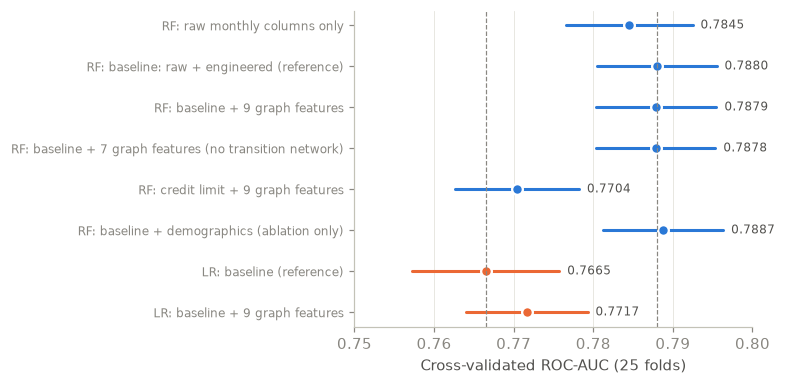

In [13]:
fig, ax = plt.subplots(figsize=(7.2, 3.6))
order = ablation_cv.iloc[::-1].reset_index(drop=True)
for i, r in order.iterrows():
    colour = BLUE if r.model == "Random Forest" else ORANGE
    ax.plot([r.roc_ci_low, r.roc_ci_high], [i, i], color=colour, lw=2, solid_capstyle="round")
    ax.plot(r.cv_roc_auc, i, "o", color=colour, ms=7, mec="white", mew=1.5)
    ax.text(r.roc_ci_high + 0.001, i, f"{r.cv_roc_auc:.4f}", va="center", fontsize=8, color=INK2)
for ref in ["A", "LR-A"]:
    ax.axvline(ablation_cv.set_index("feature_set").loc[ref, "cv_roc_auc"], color=MUTED, ls="--", lw=0.8)
ax.set_yticks(range(len(order)), [f"{r.model.replace('Random Forest', 'RF').replace('Logistic regression', 'LR')}: {r.description}" for r in order.itertuples()], fontsize=8)
ax.set_xlabel("Cross-validated ROC-AUC (25 folds)")
ax.grid(axis="x", color=GRID, lw=0.5); ax.set_axisbelow(True)
ax.set_xlim(0.75, 0.80)
fig.tight_layout(); fig.savefig(C.FIGURES / "final_ablation.png", dpi=150)

**Reading.** For the **Random Forest**, adding the graph features changes nothing: the difference interval sits around zero in CV and on the test set. On their own the graph features reach about 0.77, so they carry real signal, but the forest already learns the same order patterns from the raw monthly columns.
For **logistic regression**, the graph features give a small but reliable gain in CV and on the test set, because a linear model cannot build "late → recovered → late again" patterns by itself. Even with that gain, logistic regression stays below the forest.
Adding demographics to the forest moves the score by less than the noise, which is one more reason to leave them out.

## 4. Calibration of the probability model the score uses

The score's biggest factor reads the model output as a probability ("0.30 = about 30 in 100 similar customers miss a payment"). That is only fair if the probabilities are **calibrated**.
Notebook 07 chose model A (the graph did not reliably improve it) and calibrated it with isotonic regression inside cross-validation. Training customers get out-of-fold probabilities, test customers get the final model's.
We report the **Brier score** (mean squared error of the probability; lower is better), the **Brier skill** against always predicting the base rate, the **expected calibration error** (average gap between predicted and observed rate over 10 equal-size bins), and the **calibration slope and intercept** (1 and 0 when perfect).

In [14]:
pdc = pd.read_parquet(C.MODELS / "pd_calibrated.parquet").set_index("customer_id")
assert (pdc.model == "A").all()
pd_test, pd_train = pdc.loc[ids_te, "pd"].to_numpy(), pdc.loc[ids_tr, "pd"].to_numpy()
cal = pd.DataFrame({"raw forest score, test": E.calibration_summary(yt, preds["RF A"]),
                    "calibrated PD, test": E.calibration_summary(yt, pd_test),
                    "calibrated PD, train (out-of-fold)": E.calibration_summary(y, pd_train)})
cal_boot = E.bootstrap_metrics(yt, {"raw forest score": preds["RF A"], "calibrated PD": pd_test})
R["calibration"] = {"summary": cal.to_dict(), "bootstrap": cal_boot.to_dict("records")}
display(cal.round(4))
cal_boot.round(4)

,"raw forest score, test","calibrated PD, test","calibrated PD, train (out-of-fold)"
brier,0.1732,0.1346,0.1332
brier_base_rate,0.1723,0.1723,0.1723
brier_skill,-0.0055,0.2183,0.2270
ece,0.1824,0.0108,0.0052
mean_predicted,0.4035,0.2219,0.2217
observed_rate,0.2212,0.2212,0.2212
calibration_intercept,-1.1343,-0.0589,-0.0225
calibration_slope,0.9403,0.9494,0.9823


,model,metric,value,ci_low,ci_high
0,raw forest score,roc_auc,0.7800,0.7658,0.7950
1,raw forest score,pr_auc,0.5575,0.5302,0.5876
2,raw forest score,brier,0.1732,0.1682,0.1781
3,calibrated PD,roc_auc,0.7800,0.7657,0.7952
4,calibrated PD,pr_auc,0.5560,0.5290,0.5861
5,calibrated PD,brier,0.1346,0.1286,0.1404


**Reliability curve on the test set.** Each dot is one tenth of the test customers, ordered by predicted probability: average prediction (x) against the share who actually missed the next payment (y), with a 95% interval. On the diagonal = calibrated.

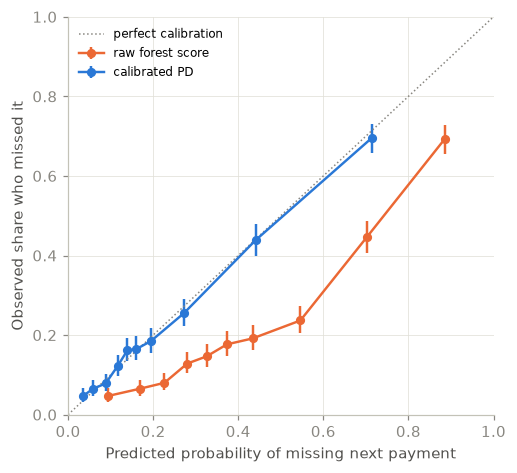

In [15]:
fig, ax = plt.subplots(figsize=(4.8, 4.4))
for p, lab, colour in [(preds["RF A"], "raw forest score", ORANGE), (pd_test, "calibrated PD", BLUE)]:
    rt = E.reliability_table(yt, p)
    ax.errorbar(rt.predicted, rt.observed, yerr=[rt.observed - rt.ci_low, rt.ci_high - rt.observed], fmt="o-", color=colour,
                ms=5, lw=1.6, capsize=0, label=lab)
ax.plot([0, 1], [0, 1], ls=":", color=MUTED, lw=1, label="perfect calibration")
ax.set_xlim(0, 1); ax.set_ylim(0, 1)
ax.set_xlabel("Predicted probability of missing next payment"); ax.set_ylabel("Observed share who missed it")
ax.grid(color=GRID, lw=0.5); ax.set_axisbelow(True); ax.legend(frameon=False, fontsize=8, loc="upper left")
fig.tight_layout(); fig.savefig(C.FIGURES / "final_calibration.png", dpi=150)

**Reading.** The raw forest score is trained with balanced class weights, so it deliberately over-predicts: its average is 0.40 against a real rate of 0.22, and its Brier score is slightly *worse* than always predicting the base rate. After isotonic calibration the average matches (0.222), the Brier score falls from 0.173 to 0.135 (22% better than the base-rate predictor), the expected calibration error falls from 0.18 to 0.011, and the slope and intercept (0.95 and −0.06) are close to perfect. Ranking quality does not change (test ROC-AUC 0.780 both ways), because calibration re-labels the scores without re-ordering customers. The slope just under 1 means the most extreme predictions are very slightly too extreme.

## 5. Credit-increase score: how the labels relate to real outcomes

Two request scenarios: **3 × the customer's typical monthly payment** (the project's main, own-scale framing) and a **fixed 30,000 for everyone** (the original example).
There are no real increase outcomes, so this is a **proxy check**: on test customers, do worse labels go with more missed payments? Because the biggest factor *is* the model's prediction, the full-score check is partly circular. So we run it three ways:
1. the full score;
2. with the model-risk factor's weight set to zero (the version notebook 08 reported), which **still uses the model through the "predicted risk ≥ 50%" safety check**;
3. with the model removed completely (factor *and* that safety check), the only fully non-circular version.

In [16]:
import copy
inp = S.load_scoring_inputs().merge(wide[["customer_id"] + C.DEMOGRAPHICS])
cfg = S.load_config()
SCEN = {"3 x typical payment": lambda d: S.relative_increase(d, "payment_multiple", 3), "fixed 30,000": lambda d: 30000}
ORDER = [S.BAND_SUPPORT, S.BAND_REVIEW, S.BAND_NOT, S.BAND_INSUFFICIENT]
w_nopd = {k: v["weight"] for k, v in cfg["components"].items()}; w_nopd["model_risk"] = 0
w_nopd = {k: v / sum(w_nopd.values()) for k, v in w_nopd.items()}
cfg_no_gate = copy.deepcopy(cfg); cfg_no_gate["gates"]["high_risk_pd"] = 2.0   # a probability never reaches 2, so the gate never fires
scored, band_rows = {}, []
for name, inc in SCEN.items():
    res = S.score(inp, inc(inp), cfg)
    scored[name] = pd.concat([inp, res.drop(columns="customer_id")], axis=1)
    test = scored[name][scored[name].split == "test"]
    nopd = S.score(test, inc(test), cfg, weights=w_nopd)
    nomodel = S.score(test, inc(test), cfg_no_gate, weights=w_nopd)
    for version, bands in [("full score", test.band), ("model-risk factor removed (PD gate kept)", nopd.band.set_axis(test.index)),
                           ("model removed completely", nomodel.band.set_axis(test.index))]:
        t = ST.default_rate_table(bands, test[C.TARGET]).reindex(ORDER).dropna(how="all")
        share_all = scored[name].band.value_counts(normalize=True) if version == "full score" else None
        for band, r in t.iterrows():
            band_rows.append({"scenario": name, "version": version, "band": band, "test_customers": int(r.n),
                              "miss_rate": r.default_rate, "ci_low": r.ci_low, "ci_high": r.ci_high,
                              "share_all_customers": float(share_all[band]) if share_all is not None else None})
bands = pd.DataFrame(band_rows)
bands.to_csv(C.TABLES / "final_band_outcomes.csv", index=False)
R["bands"] = bands.replace({np.nan: None}).to_dict("records")
bands.round(3)

,scenario,version,band,test_customers,miss_rate,ci_low,ci_high,share_all_customers
0,3 x typical payment,full score,Supportable in this scenario,3734,0.110,0.100,0.120,0.625
1,3 x typical payment,full score,Review,320,0.322,0.273,0.375,0.055
2,3 x typical payment,full score,Not supportable in this scenario,868,0.620,0.587,0.652,0.143
3,3 x typical payment,full score,Insufficient behavioural evidence,1078,0.255,0.230,0.282,0.177
4,3 x typical payment,model-risk factor removed (PD gate kept),Supportable in this scenario,3707,0.114,0.104,0.124,NaN
5,3 x typical payment,model-risk factor removed (PD gate kept),Review,437,0.279,0.239,0.323,NaN
6,3 x typical payment,model-risk factor removed (PD gate kept),Not supportable in this scenario,778,0.654,0.620,0.687,NaN
7,3 x typical payment,model-risk factor removed (PD gate kept),Insufficient behavioural evidence,1078,0.255,0.230,0.282,NaN
8,3 x typical payment,model removed completely,Supportable in this scenario,3707,0.114,0.104,0.124,NaN
9,3 x typical payment,model removed completely,Review,466,0.298,0.258,0.341,NaN


**Stability of the score to its hand-set weights and breakpoints** (from notebook 08, at the 30,000 request): every weight changed by ±20% and every breakpoint by ±10%, one at a time.

In [17]:
stab = pd.read_csv(C.TABLES / "scenario_stability.csv")
R["stability"] = {"changes_tested": len(stab), "min_spearman": float(stab.spearman_vs_original.min()),
                  "max_band_flips": float(stab.band_flips.max()),
                  "worst_change": stab.loc[stab.band_flips.idxmax(), "change"]}
pd.Series(R["stability"])

changes_tested                     22
min_spearman                 0.996859
max_band_flips               0.030033
worst_change      weight payback x1.2
dtype: object

**Reading.** With the 3 × typical payment request, *Supportable* customers missed the next payment 11.0% of the time, *Review* 32.2% and *Not supportable* 62.0%, against a 22.1% average. **With the model removed completely** the order holds (11.4% → 29.8% → 65.8%), so the behavioural and request-size factors carry real risk information by themselves; the "predicted risk ≥ 50%" safety check made almost no difference to this check. *Insufficient evidence* customers (25.5%) sit near the average, as expected for a group the score declines to judge.
Changing any weight by ±20% or any breakpoint by ±10% keeps the ranking almost identical (Spearman ≥ 0.997) and changes the label of at most 3.0% of customers.
This is a **necessary, not sufficient** check: missing a payment is not the same as an increase going badly, and the data has no increase outcomes.

## 6. Fairness audit of the suitability score

**Step 1: confirm the protected attributes are not inputs.** The probability model (feature set A) and the score's required inputs contain none of sex, age, education or marital status. As a direct check, we shuffle those four columns across customers and confirm every score and label is unchanged.

In [18]:
assert not set(C.DEMOGRAPHICS) & set(fs["A"]), "a demographic is a model input"
assert not set(C.DEMOGRAPHICS) & set(S.REQUIRED), "a demographic is a score input"
rng = np.random.default_rng(C.SEED)
shuffled = inp.copy()
for c in C.DEMOGRAPHICS:
    shuffled[c] = rng.permutation(shuffled[c].to_numpy())
inc3 = SCEN["3 x typical payment"]
a, b = S.score(inp, inc3(inp), cfg), S.score(shuffled, inc3(shuffled), cfg)
invariant = bool((a.score.to_numpy() == b.score.to_numpy()).all() and (a.band.to_numpy() == b.band.to_numpy()).all())
R["fairness_invariance"] = {"demographics_in_model": False, "demographics_in_score": False, "shuffle_invariant": invariant}
assert invariant
R["fairness_invariance"]

{'demographics_in_model': False,
 'demographics_in_score': False,
 'shuffle_invariant': True}

**Step 2: measure outcomes per group anyway.** Not using an attribute does not guarantee equal treatment, because other inputs (credit limit, payment size, late history) can differ between groups. Population: all 30,000 customers; every probability is out-of-sample, so no customer is scored by a model that saw their own outcome.

| Measure | Question it answers |
|---|---|
| `selection_rate` | What share of the group is labelled *Supportable*? |
| `selection_ratio_vs_max` | Selection rate divided by the most-favoured group's. 0.8 is a common rule-of-thumb flag (the US "four-fifths" guideline), used here only as a reference point, not a legal test. |
| `observed_miss_rate`, `mean_pd` | The group's real miss rate and its average predicted probability. Close together = the model is calibrated for that group. |
| `miss_rate_if_supportable` | Among customers labelled *Supportable*, how many missed the next payment? Similar values = the label means the same thing for every group. |
| `supportable_among_non_missers` | Among customers who did **not** miss a payment, what share was labelled *Supportable*? Similar values = equally good customers get the favourable label equally often ("equal opportunity"). |

In [19]:
ATTRS = {"sex_group": "sex", "age_group": "age band", "education_group": "education", "marriage_group": "marital status"}
COLS = ["n", "selection_rate", "selection_ratio_vs_max", "observed_miss_rate", "mean_pd",
        "miss_rate_if_supportable", "miss_if_sup_ci_low", "miss_if_sup_ci_high", "supportable_among_non_missers"]
audit_rows, disparity_rows, grouped = [], [], {}
for scen_name, df in scored.items():
    g = E.add_groups(df)
    grouped[scen_name] = g
    for attr, label in ATTRS.items():
        t = E.group_audit(g, attr)
        audit_rows += [{"scenario": scen_name, "attribute": label, "group": grp, **{c: float(t.loc[grp, c]) for c in COLS}} for grp in t.index]
        disparity_rows.append({"scenario": scen_name, "attribute": label, **E.disparity_summary(t)})
audit = pd.DataFrame(audit_rows)
audit.to_csv(C.TABLES / "fairness_audit.csv", index=False)
disparity = pd.DataFrame(disparity_rows)
R["fairness_audit"] = audit.to_dict("records")
R["fairness_disparity"] = disparity.to_dict("records")
audit[audit.scenario == "3 x typical payment"].drop(columns="scenario").round(3)

,attribute,group,n,selection_rate,selection_ratio_vs_max,observed_miss_rate,mean_pd,miss_rate_if_supportable,miss_if_sup_ci_low,miss_if_sup_ci_high,supportable_among_non_missers
0,sex,female,18112.0,0.636,1.000,0.208,0.213,0.107,0.102,0.113,0.716
1,sex,male,11888.0,0.610,0.959,0.242,0.234,0.127,0.120,0.135,0.702
2,age band,21-24,2685.0,0.603,0.941,0.272,0.280,0.134,0.118,0.151,0.717
3,age band,25-34,13011.0,0.641,1.000,0.203,0.212,0.107,0.100,0.114,0.718
4,age band,35-44,9018.0,0.621,0.969,0.219,0.212,0.117,0.109,0.125,0.702
5,age band,45-54,4233.0,0.613,0.956,0.239,0.229,0.123,0.111,0.137,0.706
6,age band,55+,1053.0,0.575,0.896,0.267,0.255,0.119,0.096,0.147,0.690
7,education,graduate school,10585.0,0.626,0.864,0.192,0.193,0.096,0.089,0.103,0.701
8,education,high school,4917.0,0.601,0.830,0.252,0.254,0.131,0.120,0.144,0.698
9,education,other / unknown,468.0,0.724,1.000,0.071,0.165,0.062,0.041,0.093,0.731


**Largest gaps per attribute, for both scenarios.** A selection ratio below 0.8 would be a flag; the range columns show the lowest and highest group.

In [20]:
disparity.round(3)

,scenario,attribute,min_selection_ratio,selection_rate_range,miss_if_supportable_range,equal_opportunity_gap
0,3 x typical payment,sex,0.959,"(0.6096063257065949, 0.6355454946996466)","(0.10711493354182955, 0.12708707051193596)",0.015
1,3 x typical payment,age band,0.896,"(0.5745489078822412, 0.6409960802397972)","(0.10683453237410072, 0.1340333539221742)",0.028
2,3 x typical payment,education,0.830,"(0.6013829570876551, 0.7243589743589743)","(0.061946902654867256, 0.13121406831247887)",0.033
3,3 x typical payment,marital status,0.949,"(0.6073651072552896, 0.6403157103482836)","(0.10839366073175503, 0.1625)",0.025
4,"fixed 30,000",sex,0.864,"(0.3966184387617766, 0.4588118374558304)","(0.08471720818291216, 0.09840933191940615)",0.059
5,"fixed 30,000",age band,0.483,"(0.2271880819366853, 0.4708323726077934)","(0.08129285014691479, 0.1111111111111111)",0.263
6,"fixed 30,000",education,0.659,"(0.35509456985967053, 0.5384615384615384)","(0.047619047619047616, 0.1013745704467354)",0.148
7,"fixed 30,000",marital status,0.692,"(0.3050397877984085, 0.44073504648949413)","(0.08243831640058055, 0.10434782608695652)",0.162


**Where do the gaps come from?** Average points each factor adds or removes, per group (3 × typical payment scenario), next to the group's typical credit limit, typical payment and late months. Because the score uses none of the attributes, any gap must flow through these inputs.

In [21]:
contrib_cols = [c for c in grouped["3 x typical payment"].columns if c.startswith("contrib_")]
drivers = []
for attr, label in ATTRS.items():
    g = grouped["3 x typical payment"]
    d = g.groupby(attr)[contrib_cols].mean()
    d.columns = [c.replace("contrib_", "pts_") for c in d.columns]
    d["median_limit"] = g.groupby(attr).credit_limit.median()
    d["median_typical_payment"] = g.groupby(attr).pay_median.median()
    d["mean_late_months"] = g.groupby(attr).late_months.mean()
    d["insufficient_evidence_share"] = g.groupby(attr).band.apply(lambda b: (b == S.BAND_INSUFFICIENT).mean())
    drivers.append(d.assign(attribute=label).reset_index(names="group"))
drivers = pd.concat(drivers, ignore_index=True)
drivers.to_csv(C.TABLES / "fairness_drivers.csv", index=False)
R["fairness_drivers"] = drivers.to_dict("records")
drivers.set_index(["attribute", "group"]).round(2)

pts_model_risk  pts_repayment  pts_coverage  pts_payback  pts_request_vs_limit  pts_utilization  median_limit  median_typical_payment  mean_late_months  \
attribute      group                                                                                                                                                                      
sex            female                     8.08           6.23          0.37         4.88                  4.95             0.97      150000.0                 1804.25              0.78   
               male                       7.03           5.76         -0.40         4.88                  4.94             0.82      130000.0                 1650.00              0.92   
age band       21-24                      4.88           5.02         -1.52         5.21                  4.90             0.64       50000.0                 1208.50              1.10   
               25-34                      8.11           6.17          0.06         4.96                  4.95             0.99      150000.0                 1963.50              0.81   
               35-44                      8.15           6.27          0.56         4.71                  4.95             0.95      180000.0                 1977.00              0.77   
               45-54                      7.39           6.01          0.14         4.87                  4.95             0.79      130000.0                 1601.00              0.85   
               55+                        6.20           5.37         -0.40         4.55                  4.95             0.63      120000.0                 1473.00              0.98   
education      graduate school            9.00           6.60          1.65         4.41                  4.95             1.13      200000.0                 2000.00              0.67   
               high school                6.17           5.42         -0.78         5.04                  4.93             0.73       80000.0                 1500.00              0.99   
               other / unknown           10.58           8.25          0.43         4.46                  4.93             0.64      170000.0                 2184.00              0.23   
               university                 7.08           5.78         -0.84         5.20                  4.95             0.81      110000.0                 1712.50              0.93   
marital status married                    7.62           5.97          0.31         4.79                  4.96             0.91      160000.0                 1801.50              0.85   
               other / unknown            6.51           5.77         -0.53         5.15                  4.90             0.68       60000.0                 1250.00              0.88   
               single                     7.73           6.12         -0.12         4.95                  4.94             0.90      130000.0                 1750.00              0.82   

                                insufficient_evidence_share  
attribute      group                                         
sex            female                                  0.18  
               male                                    0.17  
age band       21-24                                   0.09  
               25-34                                   0.17  
               35-44                                   0.20  
               45-54                                   0.19  
               55+                                     0.19  
education      graduate school                         0.23  
               high school                             0.15  
               other / unknown                         0.19  
               university                              0.14  
marital status married                                 0.19  
               other / unknown                         0.14  
               single                                  0.16

**Inside the *Supportable* label.** For customers labelled *Supportable* (3 × typical payment): their average predicted risk, the share who actually missed, and their average score. If predicted and observed match, a group's higher miss rate is visible to the model (its customers sit lower in the band); if observed is above predicted, the model under-predicts that group's risk.

In [22]:
sup = grouped["3 x typical payment"][grouped["3 x typical payment"].band == S.BAND_SUPPORT]
within = []
for attr, label in ATTRS.items():
    t = sup.groupby(attr).agg(n=("pd", "size"), mean_predicted=("pd", "mean"), observed=(C.TARGET, "mean"), mean_score=("score", "mean"))
    within.append(t.assign(attribute=label).reset_index(names="group"))
within = pd.concat(within, ignore_index=True)
within["observed_minus_predicted"] = within.observed - within.mean_predicted
R["fairness_within_supportable"] = within.to_dict("records")
within.set_index(["attribute", "group"]).round(3)

n  mean_predicted  observed  mean_score  observed_minus_predicted
attribute      group                                                                                 
sex            female           11511           0.112     0.107      85.516                    -0.005
               male              7247           0.118     0.127      84.527                     0.009
age band       21-24             1619           0.149     0.134      82.363                    -0.015
               25-34             8340           0.110     0.107      85.394                    -0.003
               35-44             5600           0.109     0.117      85.830                     0.008
               45-54             2594           0.121     0.123      84.786                     0.003
               55+                605           0.122     0.119      84.000                    -0.003
education      graduate school   6626           0.104     0.096      87.089                    -0.008
               high school       2957           0.127     0.131      83.789                     0.004
               other / unknown    339           0.109     0.062      85.165                    -0.047
               university        8836           0.119     0.125      84.116                     0.007
marital status married           8296           0.111     0.121      85.532                     0.010
               other / unknown    240           0.140     0.162      83.223                     0.022
               single           10222           0.117     0.108      84.855                    -0.008

**Proxy strength.** How well can the score's own inputs predict each attribute? A cross-validated ROC-AUC of 0.5 means the inputs carry no information about it; higher means the inputs partly act as a proxy, so gaps can appear even though the attribute is never used.

In [23]:
g = grouped["3 x typical payment"]
proxy_inputs = ["pd", "late_months", "status_latest", "coverage_median", "pay_median", "util_latest", "credit_limit", "inactive_flag"]
proxy = E.proxy_strength(g, proxy_inputs, {"male": (g.sex == 1).astype(int), "age under 30": (g.age < 30).astype(int),
                                           "graduate school": (g.education == 1).astype(int), "married": (g.marriage == 1).astype(int)})
R["fairness_proxy"] = proxy.to_dict("records")
proxy.round(3)

,attribute,positive_share,roc_auc_from_score_inputs
0,male,0.396,0.553
1,age under 30,0.321,0.651
2,graduate school,0.353,0.681
3,married,0.455,0.567


**Test customers only.** The same disparity summary on the 6,000 held-out customers, to show the picture does not depend on including training customers.

In [24]:
test_disp = []
for attr, label in ATTRS.items():
    gt = grouped["3 x typical payment"]
    test_disp.append({"attribute": label, **E.disparity_summary(E.group_audit(gt[gt.split == "test"], attr))})
test_disp = pd.DataFrame(test_disp)
R["fairness_disparity_test_only"] = test_disp.to_dict("records")
test_disp.round(3)

,attribute,min_selection_ratio,selection_rate_range,miss_if_supportable_range,equal_opportunity_gap
0,sex,0.990,"(0.6186511240632806, 0.6247915508615898)","(0.10631672597864769, 0.11574697173620457)",0.004
1,age band,0.919,"(0.589648798521257, 0.6417791898332009)","(0.09715346534653466, 0.12333965844402277)",0.031
2,education,0.855,"(0.6045364891518737, 0.7073170731707317)","(0.05172413793103448, 0.15171288743882544)",0.029
3,marital status,0.873,"(0.6053487531622697, 0.6933333333333334)","(0.0981564524165421, 0.12417910447761193)",0.031


**Figure.** Left: share labelled *Supportable* per group, both scenarios. Right: share of *Supportable* customers who then missed a payment, with 95% intervals (3 × typical payment).

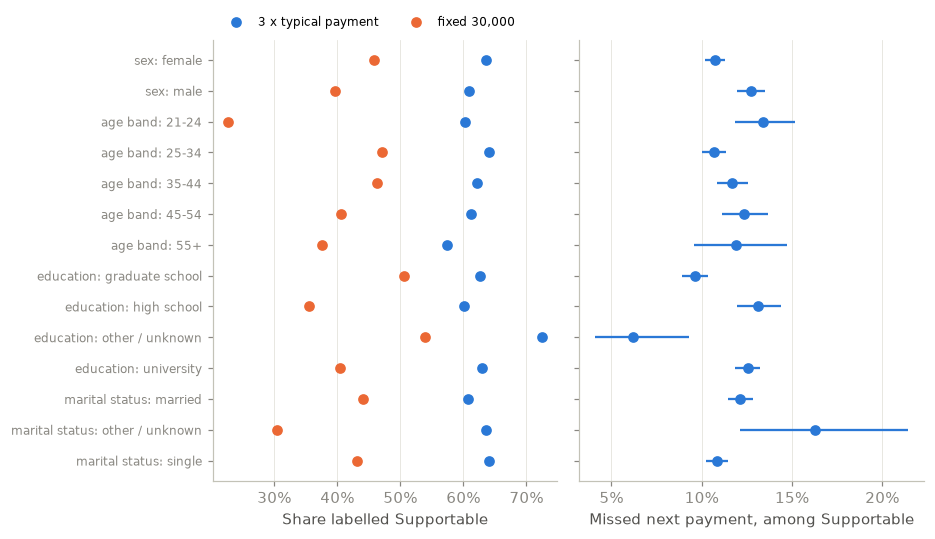

In [25]:
a3 = audit[audit.scenario == "3 x typical payment"].reset_index(drop=True)
a30 = audit[audit.scenario == "fixed 30,000"].set_index(["attribute", "group"])
labels = [f"{r.attribute}: {r.group}" for r in a3.itertuples()]
ypos = np.arange(len(a3))[::-1]
fig, (l, r_) = plt.subplots(1, 2, figsize=(8.6, 5.0), sharey=True)
l.plot(a3.selection_rate, ypos, "o", color=BLUE, ms=6, label="3 x typical payment")
l.plot([a30.loc[(r.attribute, r.group), "selection_rate"] for r in a3.itertuples()], ypos, "o", color=ORANGE, ms=6, label="fixed 30,000")
l.set_xlabel("Share labelled Supportable"); l.legend(frameon=False, fontsize=8, loc="lower left", bbox_to_anchor=(0, 1.0), ncol=2)
r_.errorbar(a3.miss_rate_if_supportable, ypos, xerr=[a3.miss_rate_if_supportable - a3.miss_if_sup_ci_low, a3.miss_if_sup_ci_high - a3.miss_rate_if_supportable],
            fmt="o", color=BLUE, ms=6, capsize=0, lw=1.5)
r_.set_xlabel("Missed next payment, among Supportable")
for axx in (l, r_):
    axx.grid(axis="x", color=GRID, lw=0.5); axx.set_axisbelow(True)
    axx.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
l.set_yticks(ypos, labels, fontsize=8)
fig.tight_layout(); fig.savefig(C.FIGURES / "final_fairness.png", dpi=150)

**Reading.**
* **Requests sized to the customer (3 × typical payment) give similar outcomes across groups.** Every group's *Supportable* rate is at least 0.83 of the most-favoured group's (lowest: high-school education), above the 0.8 reference point. Among customers who did **not** go on to miss a payment, the share labelled *Supportable* differs by at most 3.3 percentage points between the groups of any attribute.
* **A fixed 30,000 request does not.** 21–24-year-olds are labelled *Supportable* at less than half the rate of 25–34-year-olds (ratio 0.48), and high-school-educated customers at 0.66 of the top group. Even among customers who never missed a payment, 28% of 21–24-year-olds against 54% of 25–34-year-olds are *Supportable*: a 26-point equal-opportunity gap. The driver table shows why: these groups have much smaller limits and payments (median limit 50,000 for ages 21–24 against 150,000 for 25–34), so the same 30,000 is a far bigger request for them. This is the strongest argument in the project for measuring a request on the customer's own scale.
* **The label does not mean exactly the same risk in every group.** Under the 3 × request, *Supportable* customers with high-school education missed the next payment 13.1% of the time against 9.6% for graduate school, and men 12.7% against 10.7% for women. Overall, the model's average prediction is within 1.2 points of the observed rate for every group except one, but the "inside *Supportable*" table tells the two cases apart:
  * **education:** most of the gap is visible to the model. High-school customers labelled *Supportable* sit lower inside the band (average predicted risk 12.7% against 10.4%) and are predicted about right (12.7% predicted, 13.1% observed);
  * **sex:** less of it is. *Supportable* men were predicted at 11.8% but 12.7% missed, so inside this band the model slightly under-predicts men's risk, and the label is a little more lenient for them.
  * The clearest miscalibration is the small "other / unknown" education group (468 customers): 16.5% predicted, 7.1% observed overall.
* **Why any gap exists at all.** The score's inputs partly act as proxies: from them alone, "graduate school" can be predicted with ROC-AUC 0.68 and "age under 30" with 0.65 (sex 0.55, married 0.57), mainly through credit limit and payment size. Leaving the attributes out does not remove their influence, which is why it is measured here.
* **Test customers only** show the same picture (lowest selection ratio 0.855, equal-opportunity gaps of at most 3.1 points).
* **Nothing was changed in response.** The audit is descriptive. Possible remedies (group-specific cut-offs, reweighting, a different request rule) are policy trade-offs and are left as decisions, not applied silently.

## 7. Limitations
* **Old, narrow data.** One bank's customers in Taiwan, April–September 2005: six months, one card per customer, no links between customers. Results may not transfer to other markets, periods or products.
* **No income.** Payments are what customers paid toward the card, not what they earn. Affordability cannot be judged directly.
* **No real credit-increase outcomes.** The requested increase is a scenario we choose. The score can be shown to be consistent, traceable and well-behaved, and its labels line up with missed payments, but whether granting an increase would turn out well cannot be validated.
* **Hand-set weights.** The weights are transparent judgement calls; the data set the breakpoints inside each factor and the order of importance, and the stability check shows small changes barely move the labels. The request-vs-limit breakpoints are a policy assumption, not data-derived.
* **Observational model.** Predicted risk describes patterns in past behaviour; nothing here is causal, and the projected limit is never fed back into the model.
* **Graph adds explanation, not accuracy, for strong models.** Each customer's graph is a six-node chain built from the same 23 columns the models see, so it cannot add information that is not already in the table.
* **Fairness audit is descriptive.** It covers four recorded attributes with coarse, partly undocumented codes, measures gaps but does not establish their cause, and uses rule-of-thumb reference points, not a legal standard.
* **Single split.** One fixed 80/20 split (seed 42); intervals cover resampling noise, not a change of population.

## 8. Conclusion
**Does a knowledge graph of six months of card behaviour help?** For **prediction**, only for a simple model. The graph's features give logistic regression a small but reliable gain (+0.0052 ROC-AUC in cross-validation, +0.0065 on the test set, both intervals above zero), but add nothing to a Random Forest (−0.0008 on the test set, interval −0.0019 to +0.0004), which already learns the same streak and recovery patterns from the raw monthly columns. Every approach, including a graph neural network, tops out around 0.78–0.79: the limit of what these 23 columns contain. For **explanation**, yes. Without ever seeing the outcome, the graph finds clear patterns (late three months in a row: 60% miss the next payment; always paid in full: 12%), and it supplies the month-by-month evidence behind each credit-increase decision. The credit-increase score built on top uses well-calibrated probabilities, is stable to its hand-set weights, and sorts real outcomes in the right order even with the model removed. It also treats demographic groups similarly when a request is sized to each customer's own payments, which a fixed-size request does not. It remains a demonstration: with no real increase outcomes in the data, it shows how such a decision can be reasoned transparently, not that the decision is right.

**Write the report.** Saves every number collected in `R` to `outputs/reports/phase9_results.json` and generates `outputs/reports/final_report.md` from it, so the report cannot drift from the computed results.

In [26]:
R["generated_by"] = "notebooks/09_final_evaluation.ipynb"
R["generated_at"] = pd.Timestamp.now().isoformat(timespec="seconds")
(C.REPORTS / "phase9_results.json").write_text(json.dumps(R, indent=2, default=lambda o: o.item() if hasattr(o, "item") else str(o)), encoding="utf-8")
REP.write_final_report(json.loads((C.REPORTS / "phase9_results.json").read_text(encoding="utf-8")), C.REPORTS / "final_report.md")
print("wrote", C.REPORTS / "phase9_results.json", "and", C.REPORTS / "final_report.md")

wrote C:\Users\amartya kumar\graph\outputs\reports\phase9_results.json and C:\Users\amartya kumar\graph\outputs\reports\final_report.md
